In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
uploaded = files.upload()

Saving data.csv to data.csv


In [3]:
print(uploaded.keys())

dict_keys(['data.csv'])


In [4]:
df = pd.read_csv("data.csv")

print(df.head())

   Duration          Date  Pulse  Maxpulse  Calories
0        60  '2020/12/01'    110       130     409.1
1        60  '2020/12/02'    117       145     479.0
2        60  '2020/12/03'    103       135     340.0
3        45  '2020/12/04'    109       175     282.4
4        45  '2020/12/05'    117       148     406.0


In [5]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(32, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB
None
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64


In [6]:
print(df[df.isnull().any(axis=1)])

    Duration          Date  Pulse  Maxpulse  Calories
18        45  '2020/12/18'     90       112       NaN
22        45           NaN    100       119     282.0
28        60  '2020/12/28'    103       132       NaN


In [7]:
df["Calories"] = df["Calories"].fillna(df["Calories"].mean())

df = df.dropna(subset=["Date"])

print(df.isnull().sum())

Duration    0
Date        0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64


In [8]:
print(df.head(10))

   Duration          Date  Pulse  Maxpulse  Calories
0        60  '2020/12/01'    110       130     409.1
1        60  '2020/12/02'    117       145     479.0
2        60  '2020/12/03'    103       135     340.0
3        45  '2020/12/04'    109       175     282.4
4        45  '2020/12/05'    117       148     406.0
5        60  '2020/12/06'    102       127     300.0
6        60  '2020/12/07'    110       136     374.0
7       450  '2020/12/08'    104       134     253.3
8        30  '2020/12/09'    109       133     195.1
9        60  '2020/12/10'     98       124     269.0


In [9]:
print(df.duplicated().sum())

1


In [10]:
df=df.drop_duplicates()
print(df.shape)

(30, 5)


In [11]:
df["Date"] = pd.to_datetime(df["Date"])

print(df.info())

ValueError: time data "20201226" doesn't match format "'%Y/%m/%d'", at position 24. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [12]:
df["Date"] = df["Date"].astype(str).str.strip().str.strip("'\"")

df["Date"] = pd.to_datetime(df["Date"], format="mixed", errors="coerce")

print(df["Date"])
print(df.info())

0    2020-12-01
1    2020-12-02
2    2020-12-03
3    2020-12-04
4    2020-12-05
5    2020-12-06
6    2020-12-07
7    2020-12-08
8    2020-12-09
9    2020-12-10
10   2020-12-11
11   2020-12-12
13   2020-12-13
14   2020-12-14
15   2020-12-15
16   2020-12-16
17   2020-12-17
18   2020-12-18
19   2020-12-19
20   2020-12-20
21   2020-12-21
23   2020-12-23
24   2020-12-24
25   2020-12-25
26   2020-12-26
27   2020-12-27
28   2020-12-28
29   2020-12-29
30   2020-12-30
31   2020-12-31
Name: Date, dtype: datetime64[ns]
<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Duration  30 non-null     int64         
 1   Date      30 non-null     datetime64[ns]
 2   Pulse     30 non-null     int64         
 3   Maxpulse  30 non-null     int64         
 4   Calories  30 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(3)
memory usage: 1.4 K

In [13]:
df = df.sort_values(by="Date")

print(df.head(10))

   Duration       Date  Pulse  Maxpulse  Calories
0        60 2020-12-01    110       130     409.1
1        60 2020-12-02    117       145     479.0
2        60 2020-12-03    103       135     340.0
3        45 2020-12-04    109       175     282.4
4        45 2020-12-05    117       148     406.0
5        60 2020-12-06    102       127     300.0
6        60 2020-12-07    110       136     374.0
7       450 2020-12-08    104       134     253.3
8        30 2020-12-09    109       133     195.1
9        60 2020-12-10     98       124     269.0


In [14]:
print("Average Calories:", df["Calories"].mean())

Average Calories: 307.2353333333333


In [15]:
print("Maximum Calories:", df["Calories"].max())

print("Minimum Calories:", df["Calories"].min())

Maximum Calories: 479.0
Minimum Calories: 195.1


In [16]:
print("Average Pulse:", df["Pulse"].mean())

Average Pulse: 103.73333333333333


In [17]:
filtered_df = df[df["Duration"] > 60]

print(filtered_df)

   Duration       Date  Pulse  Maxpulse  Calories
7       450 2020-12-08    104       134     253.3


In [18]:
print(df.describe())

         Duration                 Date       Pulse    Maxpulse    Calories
count   30.000000                   30   30.000000   30.000000   30.000000
mean    69.500000  2020-12-15 19:12:00  103.733333  129.100000  307.235333
min     30.000000  2020-12-01 00:00:00   90.000000  101.000000  195.100000
25%     60.000000  2020-12-08 06:00:00  100.000000  120.750000  251.350000
50%     60.000000  2020-12-15 12:00:00  103.000000  128.500000  300.000000
75%     60.000000  2020-12-23 18:00:00  107.500000  132.750000  343.975000
max    450.000000  2020-12-31 00:00:00  130.000000  175.000000  479.000000
std     72.258516                  NaN    8.042702   13.215325   65.050207


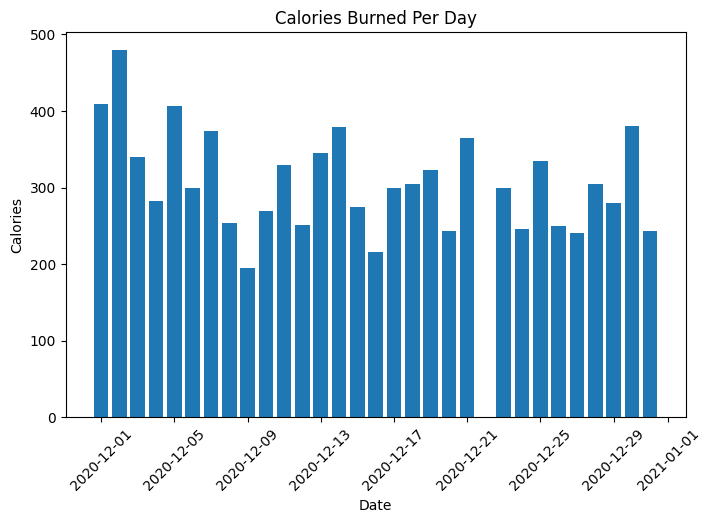

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(df["Date"], df["Calories"])

plt.xlabel("Date")
plt.ylabel("Calories")
plt.title("Calories Burned Per Day")

plt.xticks(rotation=45)
plt.show()

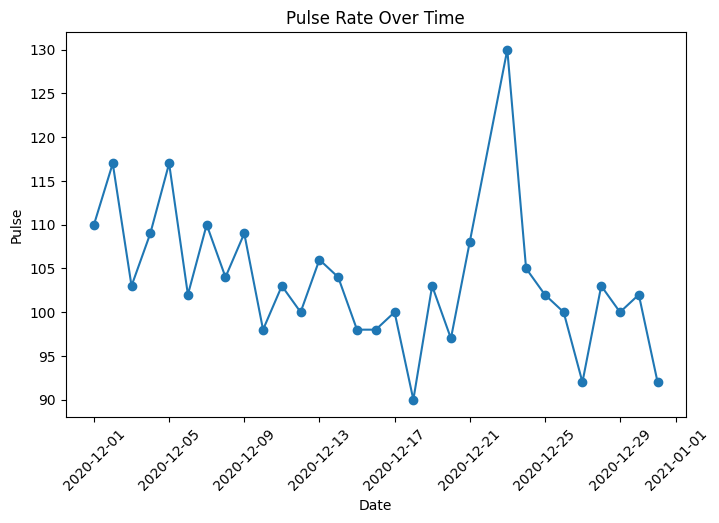

In [20]:
plt.figure(figsize=(8,5))

plt.plot(df["Date"], df["Pulse"], marker='o')

plt.xlabel("Date")
plt.ylabel("Pulse")
plt.title("Pulse Rate Over Time")

plt.xticks(rotation=45)
plt.show()

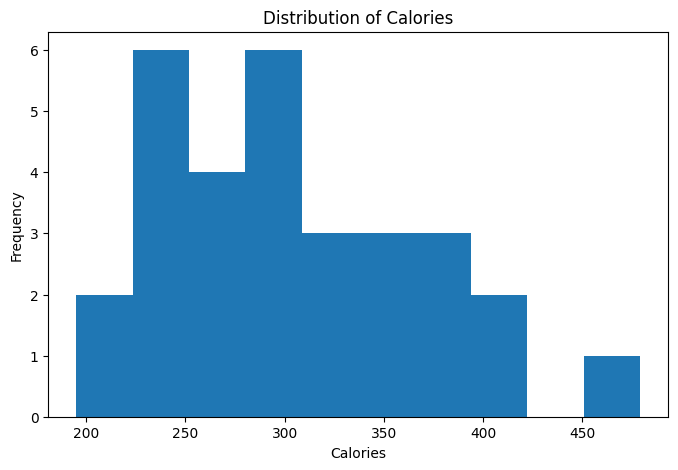

In [21]:
plt.figure(figsize=(8,5))

plt.hist(df["Calories"], bins=10)

plt.xlabel("Calories")
plt.ylabel("Frequency")
plt.title("Distribution of Calories")

plt.show()

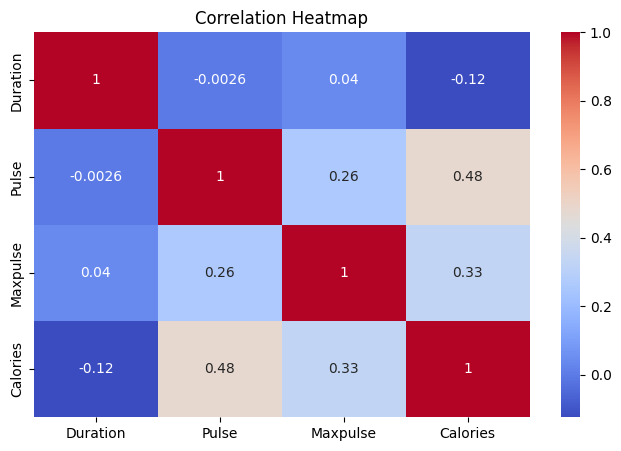

In [22]:
import seaborn as sns

plt.figure(figsize=(8,5))

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [23]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFinal Dataset:")
print(df.head())

Final Dataset Shape: (30, 5)

Missing Values:
Duration    0
Date        0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64

Duplicate Rows: 0

Final Dataset:
   Duration       Date  Pulse  Maxpulse  Calories
0        60 2020-12-01    110       130     409.1
1        60 2020-12-02    117       145     479.0
2        60 2020-12-03    103       135     340.0
3        45 2020-12-04    109       175     282.4
4        45 2020-12-05    117       148     406.0
